In [1]:
import pandas as pd
import matplotlib.pyplot as plt




## Clean data:
We note that each song within a top 200 playlist has multiple entries depending on the number of artists. to resolve this, we split into primary artists and featured artists. We then reinsert each entry back into the original dataset, to obtain 1 row per song per playlist

In [49]:
import pandas as pd

originalDF = pd.read_csv('data/Spotify_Dataset_V3.csv', delimiter=';')
dataDF = pd.read_csv('data/data.csv')

# create id, date keys to merge on (one row per (id, Date))
uniqueOrig = originalDF[['id', 'Date','Rank']].drop_duplicates()

# Prepare right-hand side for a many-to-one merge on id:
# - drop Date to avoid Date_x/Date_y
# - ensure at most one row per id
dfToMerge = (
    dataDF
    .drop(columns=['Date','Rank','Points (Total)'], errors='ignore')
    .drop_duplicates(subset='id', keep='first')
)

dfFinal = uniqueOrig.merge(
    dfToMerge,
    on=['id'],
    how='left',
    validate='m:1'   # many (dates) to one (track row)
)
dfFinal['Points (Total)'] = (201-dfFinal['Rank'])

lyrics = dfFinal[['id', 'lyrics']].drop_duplicates('id')
# lyrics.to_csv('data/lyrics.csv', index=False)

# drop lyrics from dfFinal
dfFinal = dfFinal.drop(['lyrics'], axis=1, errors='ignore')
dfFinal.columns

# summarise dfFinal
dfFinal.info()
dfFinal.head()

# Optionally verify we didn’t lose any data
print(f"Original unique entries: {len(uniqueOrig)}")
print(f"Final merged entries: {len(dfFinal)}")

dfFinal.to_csv('data/spotifyNoRowDuplicates.csv.gz', index=False, compression='gzip')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467070 entries, 0 to 467069
Data columns (total 28 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    467070 non-null  object 
 1   Date                  467070 non-null  object 
 2   Rank                  467070 non-null  int64  
 3   Title                 467070 non-null  object 
 4   Primary Artists       464696 non-null  object 
 5   Featuring Artists     94214 non-null   object 
 6   Danceability          467070 non-null  float64
 7   Energy                467070 non-null  float64
 8   Speechiness           467070 non-null  float64
 9   Acousticness          467070 non-null  float64
 10  Instrumentalness      467070 non-null  float64
 11  Valence               467070 non-null  float64
 12  Nationality           467070 non-null  object 
 13  Continent             467070 non-null  object 
 14  detected_languages    414779 non-null  object 
 15  

Text(0.5, 1.0, 'Top 100 Most Common Songs in Spotify Dataset V3')

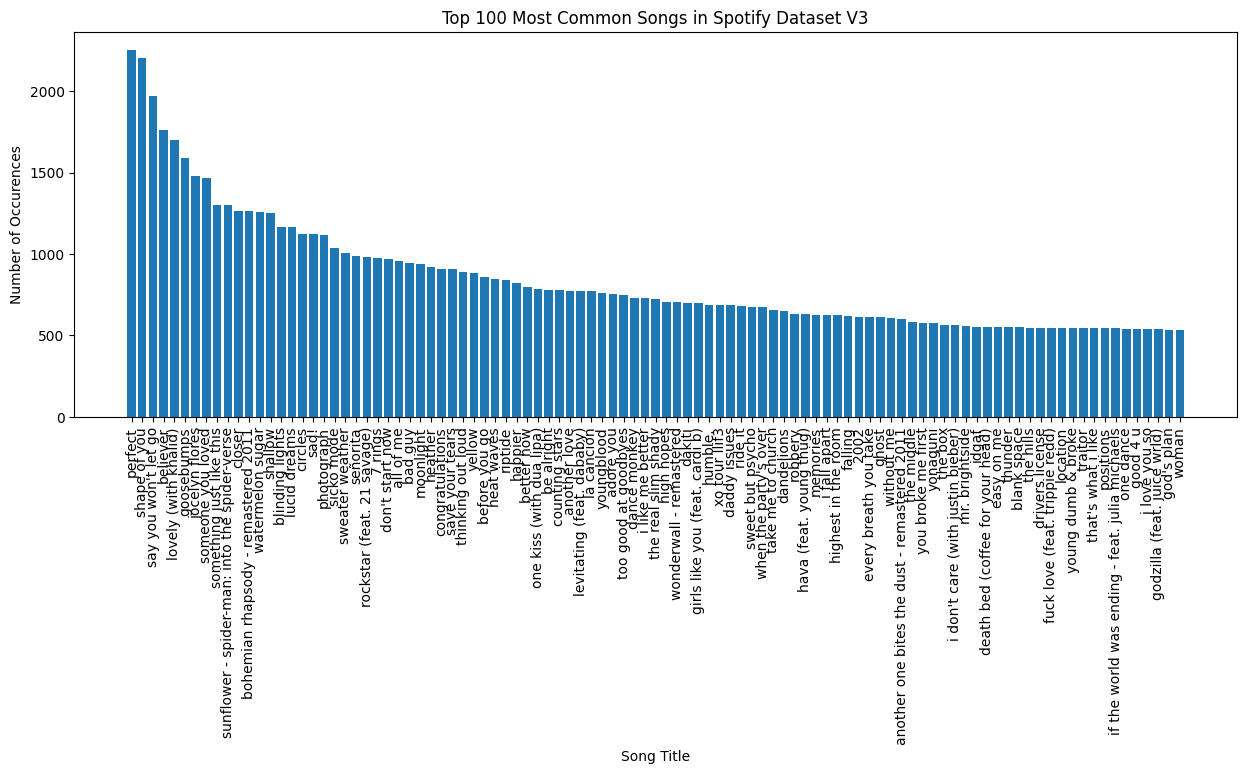

In [53]:
# count occurences of each individual id
id_counts = dfFinal.groupby('id').agg(count=('id','size'), Title=('Title','first')).reset_index().sort_values('count', ascending=False)
id_counts

# plot top 100 most common songs as bar chart
top_100 = id_counts.head(100)
plt.figure(figsize=(15,5))
plt.bar(top_100['Title'], top_100['count'])
plt.xticks(rotation=90)
plt.xlabel('Song Title')
plt.ylabel('Number of Occurences')
plt.title('Top 100 Most Common Songs in Spotify Dataset V3')
#plt.show()







# Create leaderboard of artists by total points
Include each time they appear as primary/featured artists

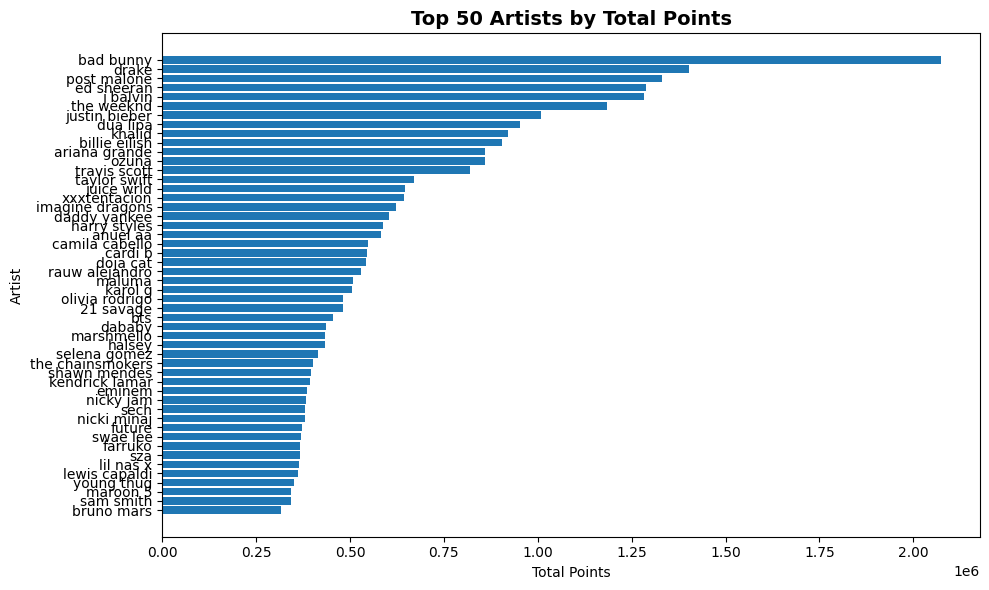

In [ ]:
df = pd.read_csv('data/spotifyNoRowDuplicates.csv')

# combine artist columns 
df['combined_artists'] = df[['Primary Artists', 'Featuring Artists']].fillna('').agg(','.join, axis=1)

# clean combined artist feature
df['combined_artists'] = df['combined_artists'].str.lower() \
    .str.replace('"', '', regex=False) \
    .str.replace("'", '', regex=False) \
    .str.split(',')
df['combined_artists'] = df['combined_artists'].apply(lambda x: [artist.strip() for artist in x if artist.strip() != ''])

df_exploded = df.explode('combined_artists')

artist_points = (
    df_exploded
    .groupby('combined_artists')['Points (Total)']
    .sum()
    .reset_index()
    .sort_values(by='Points (Total)', ascending=False)
)

top50 = artist_points.head(50)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(top50['combined_artists'], top50['Points (Total)'])
plt.gca().invert_yaxis()  # So that the top artist appears at the top

plt.title(f"Top 50 Artists by Total Points", fontsize=14, fontweight='bold')
plt.xlabel("Total Points")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()




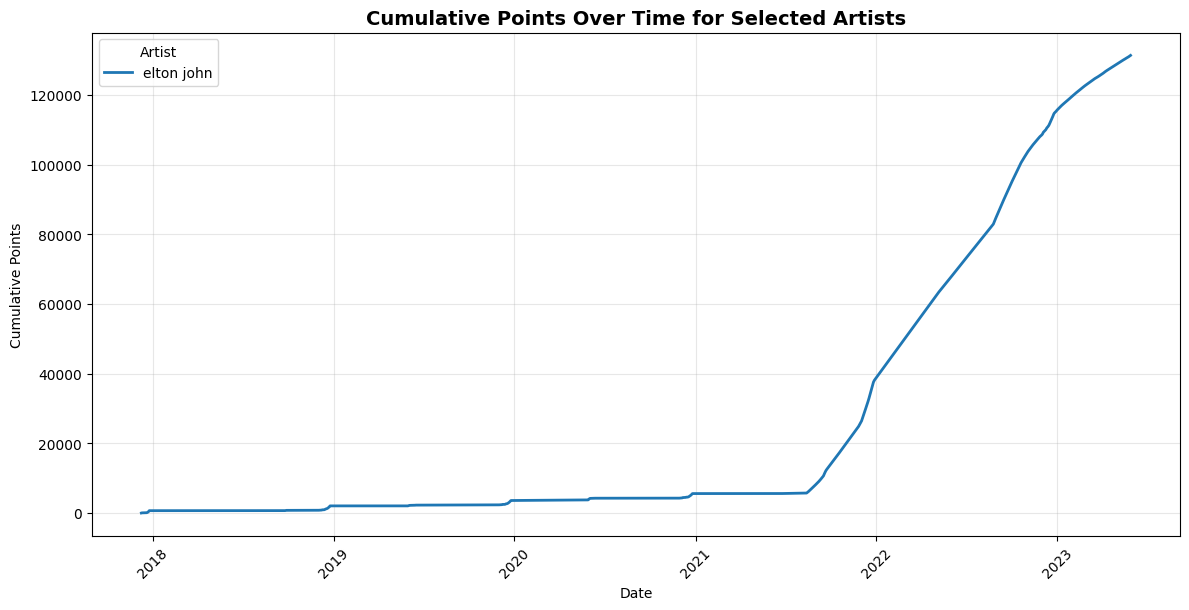

In [ ]:

artist_daily = df_exploded.groupby(['Date', 'combined_artists'])['Points (Total)'].sum().reset_index() 
artist_daily['Date'] = pd.to_datetime(artist_daily['Date'], dayfirst=True, errors='coerce')
artist_daily = artist_daily.sort_values(['combined_artists', 'Date'])


artist_daily['cumulative_points'] = (
    artist_daily.groupby('combined_artists')['Points (Total)']
    .cumsum()
)

artists_to_plot = ['elton john']


plt.figure(figsize=(12, 6))
for artist, group in artist_daily[artist_daily['combined_artists'].isin(artists_to_plot)].groupby('combined_artists'):
    plt.plot(group['Date'], group['cumulative_points'], label=artist, linewidth=2)


plt.title("Cumulative Points Over Time for Selected Artists", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Cumulative Points")
plt.legend(title="Artist")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()




# Plot Historical Popularity of individual songs

                            id       Date  Rank            Title  \
232715  0VjIjW4GlUZAMYd2vXMi3b 2020-03-21     1  blinding lights   
232518  0VjIjW4GlUZAMYd2vXMi3b 2020-03-22     1  blinding lights   
232316  0VjIjW4GlUZAMYd2vXMi3b 2020-03-23     1  blinding lights   
232114  0VjIjW4GlUZAMYd2vXMi3b 2020-03-24     1  blinding lights   
231914  0VjIjW4GlUZAMYd2vXMi3b 2020-03-25     1  blinding lights   
...                        ...        ...   ...              ...   
860     0VjIjW4GlUZAMYd2vXMi3b 2023-05-25    61  blinding lights   
661     0VjIjW4GlUZAMYd2vXMi3b 2023-05-26    62  blinding lights   
461     0VjIjW4GlUZAMYd2vXMi3b 2023-05-27    62  blinding lights   
260     0VjIjW4GlUZAMYd2vXMi3b 2023-05-28    61  blinding lights   
55      0VjIjW4GlUZAMYd2vXMi3b 2023-05-29    56  blinding lights   

       Primary Artists Featuring Artists  Danceability  Energy  Speechiness  \
232715      the weeknd               NaN         0.514    0.73         0.06   
232518      the weeknd   

/var/folders/k9/lq7z_25d2sd79_3l2tt86bsr0000gn/T/ipykernel_80755/247840836.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  allEntries['Date'] = pd.to_datetime(allEntries['Date'], dayfirst=True)


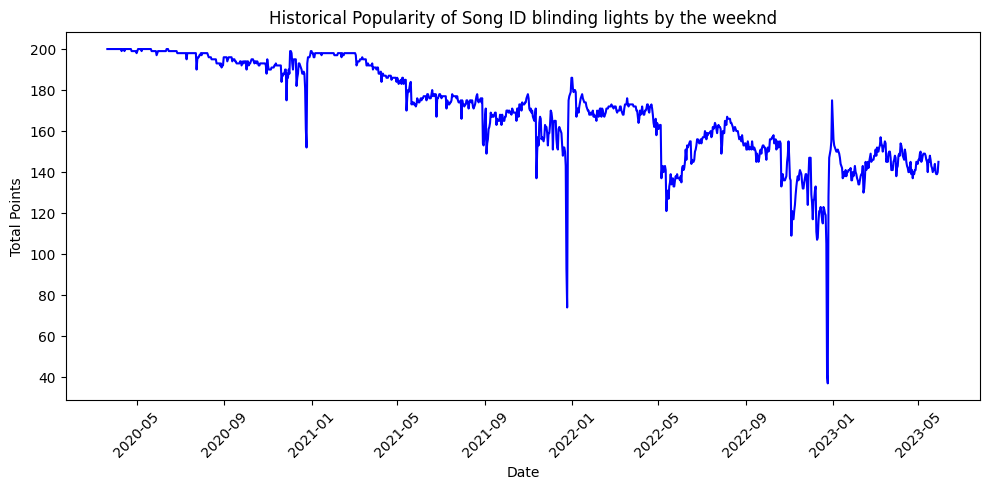

In [64]:
# want to create function which will:
# (1) search for all entries of song within dataset
# (2) sort dates
# (3) plot points over time

def historicalPopularity(df, id):
    # given song title, search for all entries of song within dataset
    allEntries = df.loc[df['id'] == id]
    allEntries['Date'] = pd.to_datetime(allEntries['Date'], dayfirst=True)
    
    # Sort allEntries by the date
    sortedAllEntries = allEntries.sort_values(by='Date')
    print(sortedAllEntries)
    
    # Plotting Points over time
    plt.figure(figsize=(10, 5))  # Set the figure size for better readability
    plt.plot(sortedAllEntries['Date'], sortedAllEntries['Points (Total)'], color='blue')

    # get title from id
    title = df.loc[df['id'] == id, 'Title'].values[0]
    artist = df.loc[df['id'] == id, 'Primary Artists'].values[0]

    # Adding titles and labels
    plt.title(f'Historical Popularity of Song ID {title} by {artist}')
    plt.xlabel('Date')
    plt.ylabel('Total Points')
    plt.xticks(rotation=45)  # Rotate date labels for better visibility
    plt.tight_layout()  # Adjust layout to make room for the rotated date labels
    plt.show()


df = pd.read_csv('data/spotifyNoRowDuplicates.csv')



id = '0VjIjW4GlUZAMYd2vXMi3b'

historicalPopularity(df, id)



# Historical popularity of artists

In [ ]:
# collect 